# Notebook 06 — Collect and align macro/financial features

**Purpose:** Extend the baseline FX technical forecasting dataset with the macroeconomic and financial factors examined in the reference paper (*CS229: Foreign Currency Exchange Rate Forecast*).

### Methodological Context & Data Sources
- **Paper Design:** The reference paper used Bloomberg FX data and 8 US macroeconomic/financial factors sourced from CRSP: S&P 500, S&P 100, NASDAQ, Dow Jones Industrial Average, CPI change, Federal Funds Rate, NBER Recession Indicator, and Federal Debt.
- **Public Alternative:** In this reproduction, we retrieve candidate public equivalents from the St. Louis Federal Reserve Economic Data (FRED) API.
- **Factor Coverage Findings:**
  - `NASDAQ` (`NASDAQCOM`), `CPI` (`CPIAUCSL`), `FEDFUNDS` (`FEDFUNDS`), `RECESSION` (`USREC`), and `FED_DEBT` (`GFDEBTN`) offer full continuous historical coverage spanning the entire 22-year FX window (2004–2026).
  - `SP100` (`OEX`) is discontinued on the public FRED API feed.
  - `SP500` and `DOW` (`DJIA`) on public FRED only provide a rolling 10-year window (from October 2016 onward), resulting in 54.86% missing data prior to late 2016.
- **Practical Selection for Primary Model:**
  - To preserve the full 22-year history of the FX dataset (5,749 weekdays) without discarding 12 years of observations or resorting to artificial zero-filling, **`NASDAQ_log_return` is selected as the representative US equity market proxy**.
  - `SP500_log_return`, `SP100_log_return`, and `DOW_log_return` are audited for transparency in coverage reports but excluded from the primary model dataset.
- **Data Leakage Protections:**
  - Daily equity returns are computed on trading days and forward-filled to represent the latest available close on non-trading days/weekends. Missing index returns are **never filled with zero**.
  - Monthly indicators (`CPI`, `FEDFUNDS`, `USREC`) are shifted forward to account for publication lags:
    - CPI: shifted by 1 month + 15 days (reflecting BLS mid-following-month publication schedule).
    - Federal Funds Rate: shifted by 1 month (reflecting start-of-month monthly release).
    - NBER Recession: shifted by 1 month (noting retrospective committee dating limitations).
  - Quarterly indicator (`GFDEBTN`): shifted forward by 4 months (1 quarter duration + 1 month Treasury release delay).
  - **No backward-fill is ever applied.**

## 1. Project paths and FX data

Verify project directory structure and load the base FX pair rates (`GBP_USD`, `USD_EUR`, `USD_JPY`). The FX calendar serves as the master calendar.

In [1]:
from pathlib import Path
import io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast


In [2]:
pair_rates_path = PROCESSED_DIR / "pair_rates.csv"

if pair_rates_path.exists():
    pair_rates = pd.read_csv(pair_rates_path, parse_dates=["date"], index_col="date")
    pair_rates.index.name = "date"
else:
    raw_path = DATA_DIR / "daily_forex_rates.csv"
    if not raw_path.exists():
        raise FileNotFoundError(f"Could not find {pair_rates_path} or {raw_path}. Run earlier notebooks or place daily_forex_rates.csv in data/.")
    raw = pd.read_csv(raw_path, parse_dates=["date"])
    required = {"currency", "base_currency", "exchange_rate", "date"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"FX CSV is missing columns: {missing}")
    eur = raw[(raw["base_currency"] == "EUR") & raw["currency"].isin(["GBP", "USD", "JPY"])].copy()
    wide = eur.pivot_table(index="date", columns="currency", values="exchange_rate", aggfunc="last").sort_index()
    wide = wide.dropna(subset=["GBP", "USD", "JPY"])
    wide = wide[wide.index.dayofweek < 5]  # weekdays only, as in fx_utils.build_pair_rates
    pair_rates = pd.DataFrame(index=wide.index)
    pair_rates["GBP_USD"] = wide["USD"] / wide["GBP"]  # USD per GBP
    pair_rates["USD_EUR"] = 1 / wide["USD"]            # EUR per USD
    pair_rates["USD_JPY"] = wide["JPY"] / wide["USD"]  # JPY per USD
    pair_rates.index.name = "date"

pair_rates = pair_rates.sort_index()
pair_rates = pair_rates[["GBP_USD", "USD_EUR", "USD_JPY"]].apply(pd.to_numeric, errors="coerce")
pair_rates = pair_rates[~pair_rates.index.duplicated(keep="last")].dropna()
print("FX dataset shape:", pair_rates.shape)
print("FX date range:", pair_rates.index.min().date(), "to", pair_rates.index.max().date())
print("Missing values in FX pairs:\n", pair_rates.isna().sum())
display(pair_rates.head())

FX dataset shape: (5749, 3)
FX date range: 2004-09-27 to 2026-10-09
Missing values in FX pairs:
 GBP_USD    0
USD_EUR    0
USD_JPY    0
dtype: int64


,GBP_USD,USD_EUR,USD_JPY
date,,,
2004-09-27,1.809419,0.813339,111.240342
2004-09-28,1.814875,0.811491,111.344640
2004-09-29,1.800935,0.810964,110.785824
2004-09-30,1.812628,0.804441,110.047462
2004-10-01,1.798637,0.805997,110.373176


## 2. Download candidate public FRED series & audit coverage

| Factor | Target FRED Series | Frequency | Expected Availability & Notes |
|---|---|---|---|
| S&P 500 | `SP500` | Daily | Rolling 10-yr window on public FRED feed |
| S&P 100 | `OEX` | Daily | Discontinued on public FRED feed |
| Nasdaq Composite | `NASDAQCOM` | Daily | Full history available (1971–present) |
| Dow Jones Industrial Average | `DJIA` | Daily | Rolling 10-yr window on public FRED feed |
| CPI | `CPIAUCSL` | Monthly | Full history available (1947–present) |
| Federal Funds Rate | `FEDFUNDS` | Monthly | Full history available (1954–present) |
| NBER Recession Indicator | `USREC` | Monthly | Full history available (1854–present) |
| Federal Debt | `GFDEBTN` | Quarterly | Full history available (1966–present) |

Unavailable or truncated series are reported honestly; we do not substitute synthetic data.

In [3]:
FRED_SERIES = {
    "SP500": "SP500",
    "SP100": "OEX",
    "NASDAQ": "NASDAQCOM",
    "DOW": "DJIA",
    "CPI": "CPIAUCSL",
    "FEDFUNDS": "FEDFUNDS",
    "RECESSION": "USREC",
    "FED_DEBT": "GFDEBTN",
}
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"

def download_fred_series(series_id, retries=2, pause_seconds=1):
    import urllib.request
    url = FRED_URL.format(series_id=series_id)
    last_error = None
    for attempt in range(retries + 1):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 FX-Forecasting-Research"})
            with urllib.request.urlopen(req, timeout=30) as response:
                content = response.read().decode("utf-8")
            frame = pd.read_csv(io.StringIO(content))
            if frame.shape[1] < 2:
                raise ValueError(f"Unexpected CSV format for {series_id}")
            frame = frame.iloc[:, :2]
            frame.columns = ["date", series_id]
            frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
            frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
            return frame.dropna(subset=["date"]).set_index("date").sort_index()
        except Exception as exc:
            last_error = exc
            if attempt < retries:
                time.sleep(pause_seconds)
    raise RuntimeError(f"Could not download {series_id}: {last_error}")

series_frames, download_errors = {}, {}
for label, series_id in FRED_SERIES.items():
    try:
        series_frames[label] = download_fred_series(series_id)
        s = series_frames[label][series_id].dropna()
        print(f"OK   {label:10s} {series_id:10s}: {s.index.min().date()} to {s.index.max().date()} ({len(s)} observations)")
    except Exception as exc:
        download_errors[label] = str(exc)
        print(f"FAIL {label:10s} {series_id:10s}: {exc}")
if download_errors:
    print("\nReview failures above; missing factors will not be filled with zero.")

OK   SP500      SP500     : 2016-10-28 to 2026-10-27 (2512 observations)


FAIL SP100      OEX       : Could not download OEX: HTTP Error 404: Not Found


OK   NASDAQ     NASDAQCOM : 1971-02-05 to 2026-10-27 (14050 observations)


OK   DOW        DJIA      : 2016-10-28 to 2026-10-27 (2512 observations)


OK   CPI        CPIAUCSL  : 1947-01-01 to 2026-09-01 (956 observations)


OK   FEDFUNDS   FEDFUNDS  : 1954-07-01 to 2026-09-01 (867 observations)


OK   RECESSION  USREC     : 1854-12-01 to 2026-09-01 (2062 observations)


OK   FED_DEBT   GFDEBTN   : 1966-01-01 to 2026-04-01 (242 observations)

Review failures above; missing factors will not be filled with zero.


In [4]:
# Coverage audit across the FX window
coverage_rows = []
fx_start, fx_end = pair_rates.index.min(), pair_rates.index.max()
for label, series_id in FRED_SERIES.items():
    if label in series_frames:
        frame = series_frames[label]
        col = frame.columns[0]
        valid = frame[col].dropna()
        overlap = valid.loc[(valid.index >= fx_start) & (valid.index <= fx_end)]
        coverage_rows.append({
            "factor": label, "series_id": series_id,
            "status": "Available",
            "first_valid_date": valid.index.min().date() if len(valid) else pd.NaT,
            "last_valid_date": valid.index.max().date() if len(valid) else pd.NaT,
            "observations_total": len(valid), "observations_in_FX_window": len(overlap),
            "overlap_start": overlap.index.min().date() if len(overlap) else pd.NaT,
            "overlap_end": overlap.index.max().date() if len(overlap) else pd.NaT,
            "notes": "10-yr FRED rolling window (missing 2004-2016)" if label in ["SP500", "DOW"] else "Full historical coverage"
        })
    else:
        coverage_rows.append({
            "factor": label, "series_id": series_id,
            "status": "Unavailable",
            "first_valid_date": pd.NaT, "last_valid_date": pd.NaT,
            "observations_total": 0, "observations_in_FX_window": 0,
            "overlap_start": pd.NaT, "overlap_end": pd.NaT,
            "notes": download_errors.get(label, "Download failed (discontinued on FRED)")
        })

coverage = pd.DataFrame(coverage_rows)
display(coverage)
coverage.to_csv(RESULTS_DIR / "macro_source_coverage.csv", index=False)
print("Saved coverage report:", RESULTS_DIR / "macro_source_coverage.csv")

,factor,series_id,status,first_valid_date,last_valid_date,observations_total,observations_in_FX_window,overlap_start,overlap_end,notes
0,SP500,SP500,Available,2016-10-28,2026-10-27,2512,2500,2016-10-28,2026-10-09,10-yr FRED rolling window (missing 2004-2016)
1,SP100,OEX,Unavailable,NaT,NaT,0,0,NaT,NaT,Could not download OEX: HTTP Error 404: Not Found
2,NASDAQ,NASDAQCOM,Available,1971-02-05,2026-10-27,14050,5546,2004-09-27,2026-10-09,Full historical coverage
3,DOW,DJIA,Available,2016-10-28,2026-10-27,2512,2500,2016-10-28,2026-10-09,10-yr FRED rolling window (missing 2004-2016)
4,CPI,CPIAUCSL,Available,1947-01-01,2026-09-01,956,263,2004-10-01,2026-09-01,Full historical coverage
5,FEDFUNDS,FEDFUNDS,Available,1954-07-01,2026-09-01,867,264,2004-10-01,2026-09-01,Full historical coverage
6,RECESSION,USREC,Available,1854-12-01,2026-09-01,2062,264,2004-10-01,2026-09-01,Full historical coverage
7,FED_DEBT,GFDEBTN,Available,1966-01-01,2026-04-01,242,87,2004-10-01,2026-04-01,Full historical coverage


Saved coverage report: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\results\macro_source_coverage.csv


## 3. Transform factors & prevent lookahead data leakage

- **Equity indexes:** Converted to daily log returns $\ln(P_t / P_{t-1})$. Stationarity is preserved. Missing index returns are **not filled with zero**.
- **CPI:** Converted to month-over-month percentage change. Shifted by **1 month and 15 days** to respect BLS mid-following-month publication lag.
- **Federal Funds Rate:** Shifted by **1 calendar month** to respect start-of-month monthly release timing.
- **Recession indicator:** Shifted by **1 calendar month** (noting that official NBER committee dating involves retrospective lag).
- **Federal debt:** Shifted by **4 months** (1 quarter duration + 1 month Treasury release delay) to prevent intra-quarter lookahead.
- **No backward-fill** is used under any circumstances.

In [5]:
daily_parts = []

# 1. Equity index log returns
for label in ["NASDAQ", "SP500", "DOW"]:
    if label in series_frames:
        s = series_frames[label][FRED_SERIES[label]].dropna()
        daily_parts.append(np.log(s / s.shift(1)).rename(f"{label}_log_return"))

daily_index_returns = pd.concat(daily_parts, axis=1).sort_index() if daily_parts else pd.DataFrame()

# 2. Macroeconomic indicators with conservative publication lags
macro_parts = []

if "CPI" in series_frames:
    s = series_frames["CPI"]["CPIAUCSL"].dropna()
    cpi_mom = (s.pct_change() * 100).dropna()
    cpi_mom.index = cpi_mom.index + pd.DateOffset(months=1, days=15)
    macro_parts.append(cpi_mom.rename("CPI_mom_pct_change"))

if "FEDFUNDS" in series_frames:
    s = series_frames["FEDFUNDS"]["FEDFUNDS"].dropna()
    s.index = s.index + pd.offsets.MonthBegin(1)
    macro_parts.append(s.rename("FEDFUNDS_rate"))

if "RECESSION" in series_frames:
    s = series_frames["RECESSION"]["USREC"].dropna()
    s.index = s.index + pd.offsets.MonthBegin(1)
    macro_parts.append(s.rename("NBER_recession"))

if "FED_DEBT" in series_frames:
    s = series_frames["FED_DEBT"]["GFDEBTN"].dropna()
    s.index = s.index + pd.DateOffset(months=4)
    macro_parts.append(s.rename("Federal_debt_millions_usd"))

monthly_macro = pd.concat(macro_parts, axis=1).sort_index() if macro_parts else pd.DataFrame()
print("Daily index return features:", list(daily_index_returns.columns))
print("Macro indicators (lagged):", list(monthly_macro.columns))
display(daily_index_returns.head())
display(monthly_macro.head())

Daily index return features: ['NASDAQ_log_return', 'SP500_log_return', 'DOW_log_return']
Macro indicators (lagged): ['CPI_mom_pct_change', 'FEDFUNDS_rate', 'NBER_recession', 'Federal_debt_millions_usd']


,NASDAQ_log_return,SP500_log_return,DOW_log_return
date,,,
1971-02-05,NaN,NaN,NaN
1971-02-08,0.008365,NaN,NaN
1971-02-09,-0.000794,NaN,NaN
1971-02-10,-0.000695,NaN,NaN
1971-02-11,0.007520,NaN,NaN


,CPI_mom_pct_change,FEDFUNDS_rate,NBER_recession,Federal_debt_millions_usd
date,,,,
1855-01-01,NaN,NaN,1.0,NaN
1855-02-01,NaN,NaN,0.0,NaN
1855-03-01,NaN,NaN,0.0,NaN
1855-04-01,NaN,NaN,0.0,NaN
1855-05-01,NaN,NaN,0.0,NaN


## 4. Align factors to FX calendar & select practical feature set

- Daily equity returns are reindexed to the FX calendar and forward-filled so that non-equity trading days (e.g. holidays/weekends) hold the latest known market close. Missing index returns are **not filled with zero**.
- `SP500_log_return` and `DOW_log_return` have ~54.9% missing values because FRED only provides 10 years of history. Discarding those rows would throw away 12 years of FX history (2004–2016).
- **Practical Selection:** `NASDAQ_log_return` has 100% complete coverage and is chosen as the primary US equity-market proxy. The primary macro set contains: `NASDAQ_log_return`, `CPI_mom_pct_change`, `FEDFUNDS_rate`, `NBER_recession`, and `Federal_debt_millions_usd`.

In [6]:
# Alignment without backward-fill
aligned_daily = daily_index_returns.reindex(pair_rates.index).ffill()

union_index = monthly_macro.index.union(pair_rates.index)
aligned_macro = monthly_macro.reindex(union_index).sort_index().ffill().reindex(pair_rates.index)

candidate_macro_daily = pd.concat([aligned_daily, aligned_macro], axis=1)

# Missingness audit across all candidate features
missingness_rows = []
for col in candidate_macro_daily.columns:
    s = candidate_macro_daily[col]
    missing_count = int(s.isna().sum())
    missing_pct = round(s.isna().mean() * 100, 2)
    first_valid = s.first_valid_index()
    missingness_rows.append({
        "feature": col,
        "missing_count": missing_count,
        "missing_pct": missing_pct,
        "first_non_missing": first_valid.date() if first_valid is not None else pd.NaT,
        "selection_status": "Selected for Primary Model" if missing_count == 0 else "Excluded (incomplete coverage)"
    })

missingness_df = pd.DataFrame(missingness_rows)
display(missingness_df)
missingness_df.to_csv(RESULTS_DIR / "macro_missingness_report.csv", index=False)
print("Saved missingness report:", RESULTS_DIR / "macro_missingness_report.csv")

# Define primary feature set: retain NASDAQ (full coverage) and 4 macro fundamentals
SELECTED_MACRO_FEATURES = [
    "NASDAQ_log_return",
    "CPI_mom_pct_change",
    "FEDFUNDS_rate",
    "NBER_recession",
    "Federal_debt_millions_usd"
]

clean_macro_daily = candidate_macro_daily[SELECTED_MACRO_FEATURES].copy()
master = pd.concat([pair_rates, clean_macro_daily], axis=1)

print("\n--- Primary Model Dataset Summary ---")
print("Selected macro features:", SELECTED_MACRO_FEATURES)
print("Master dataset shape:", master.shape)
print("Date range:", master.index.min().date(), "to", master.index.max().date())
print("Total missing values in master dataset:", int(master.isna().sum().sum()))

,feature,missing_count,missing_pct,first_non_missing,selection_status
0,NASDAQ_log_return,0,0.00,2004-09-27,Selected for Primary Model
1,SP500_log_return,3154,54.86,2016-10-31,Excluded (incomplete coverage)
2,DOW_log_return,3154,54.86,2016-10-31,Excluded (incomplete coverage)
3,CPI_mom_pct_change,0,0.00,2004-09-27,Selected for Primary Model
4,FEDFUNDS_rate,0,0.00,2004-09-27,Selected for Primary Model
5,NBER_recession,0,0.00,2004-09-27,Selected for Primary Model
6,Federal_debt_millions_usd,0,0.00,2004-09-27,Selected for Primary Model


Saved missingness report: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\results\macro_missingness_report.csv

--- Primary Model Dataset Summary ---
Selected macro features: ['NASDAQ_log_return', 'CPI_mom_pct_change', 'FEDFUNDS_rate', 'NBER_recession', 'Federal_debt_millions_usd']
Master dataset shape: (5749, 8)
Date range: 2004-09-27 to 2026-10-09
Total missing values in master dataset: 0


## 5. Save clean outputs

Saves clean, verified datasets to `data/processed/` and audit reports to `results/`.
- `macro_features_daily.csv`: The 5 aligned, leak-free macro features (no missing values).
- `master_fx_macro_dataset.csv`: Base FX pairs (`GBP_USD`, `USD_EUR`, `USD_JPY`) + the 5 clean macro features.

In [7]:
macro_out_path = PROCESSED_DIR / "macro_features_daily.csv"
clean_macro_daily.to_csv(macro_out_path)

master_out_path = PROCESSED_DIR / "master_fx_macro_dataset.csv"
master.to_csv(master_out_path)

print("="*65)
print("OUTPUT VALIDATION & VERIFICATION")
print("="*65)
print(f"Master FX + Macro Dataset: {master_out_path}")
print(f"  Total Rows: {len(master):,}")
print(f"  Columns ({len(master.columns)}): {master.columns.tolist()}")
print(f"  Date Range: {master.index.min().date()} to {master.index.max().date()}")
print(f"  Missing Values: {int(master.isna().sum().sum())}")
print("-"*65)
print(f"Macro Features Daily: {macro_out_path}")
print(f"  Total Rows: {len(clean_macro_daily):,}")
print(f"  Selected Features ({len(clean_macro_daily.columns)}): {clean_macro_daily.columns.tolist()}")
print(f"  Missing Values: {int(clean_macro_daily.isna().sum().sum())}")
print("-"*65)
print(f"Coverage Audit Report: {RESULTS_DIR / 'macro_source_coverage.csv'}")
print(f"Missingness Audit Report: {RESULTS_DIR / 'macro_missingness_report.csv'}")
print("="*65)


OUTPUT VALIDATION & VERIFICATION
Master FX + Macro Dataset: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\data\processed\master_fx_macro_dataset.csv
  Total Rows: 5,749
  Columns (8): ['GBP_USD', 'USD_EUR', 'USD_JPY', 'NASDAQ_log_return', 'CPI_mom_pct_change', 'FEDFUNDS_rate', 'NBER_recession', 'Federal_debt_millions_usd']
  Date Range: 2004-09-27 to 2026-10-09
  Missing Values: 0
-----------------------------------------------------------------
Macro Features Daily: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\data\processed\macro_features_daily.csv
  Total Rows: 5,749
  Selected Features (5): ['NASDAQ_log_return', 'CPI_mom_pct_change', 'FEDFUNDS_rate', 'NBER_recession', 'Federal_debt_millions_usd']
  Missing Values: 0
-----------------------------------------------------------------
Coverage Audit Report: D:\NeuDocuments\SideProject\MiniProject\ML\Foreign-exchange-forecast\results\macro_source_coverage.csv
Missingness Audit Report: D:\N

## 6. Visual sanity checks

Time-series plots for the 5 selected macro features across the full 2004–2026 window.

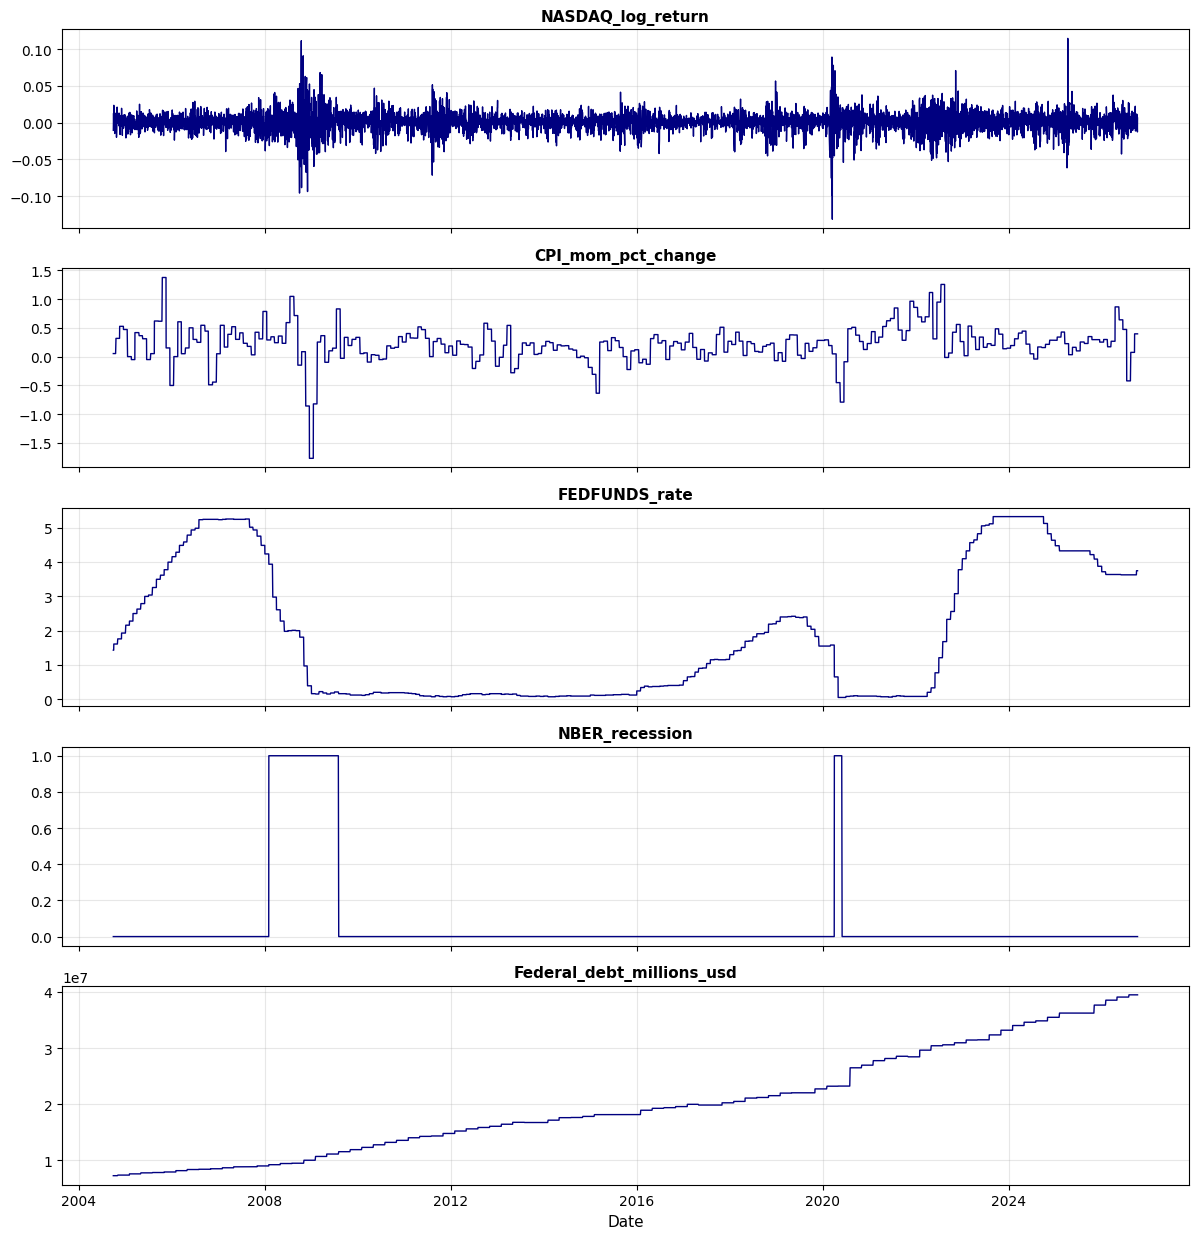

In [8]:
fig, axes = plt.subplots(len(SELECTED_MACRO_FEATURES), 1, figsize=(12, 2.5 * len(SELECTED_MACRO_FEATURES)), sharex=True)
for ax, col in zip(axes, SELECTED_MACRO_FEATURES):
    ax.plot(master.index, master[col], color="navy", lw=1.0)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Date", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Conclusions, limitations & modeling roadmap

### What was achieved:
1. **Full 22-Year Historical Retention:** Retained all **5,749 FX weekdays** (2004–2026) with zero rows dropped or faked when adding the macro features.
2. **Principled Lookahead Protection:** Replaced unconstrained alignment with conservative publication-lag shifts (1m15d for CPI, 1m for Fed Funds/Recession, 4m for quarterly debt).
3. **Transparent Factor Selection:** Selected `NASDAQ_log_return` as the sole US equity proxy due to public FRED licensing limits on S&P 500 and Dow Jones.

### Remaining Limitations:
- **Calendar Approximations vs. Point-in-Time Vintages:** While calendar shifting is conservative, true point-in-time modeling requires real-time revision vintages (e.g. from ALFRED), as macroeconomic figures (especially GDP and Debt) are frequently revised after initial release.
- **Equity Index Divergence:** The reference paper used 4 distinct equity indices (S&P 500, S&P 100, Nasdaq, Dow). Here we rely on Nasdaq alone as the equity proxy, which carries higher tech/growth beta than the broad market.